In [1]:
from pathlib import Path

ROOT = Path.cwd().parent
DATA = ROOT / "data"
RANDOM_STATE = 42

In [2]:
import pandas as pd


def count_csv_vs_image_files(csv_path: Path, image_dir: Path) -> dict[str, int]:
    """Compare image_id values in the CSV with the image files in the folder."""
    csv_ids = pd.read_csv(csv_path)["image_id"]
    file_ids = {path.stem for path in image_dir.iterdir() if path.is_file()}
    unique_csv_ids = set(csv_ids)
    return {
        "csv_rows": len(csv_ids),
        "unique_csv_ids": len(unique_csv_ids),
        "files_in_folder": len(file_ids),
        "csv_ids_without_file": len(unique_csv_ids - file_ids),
        "files_without_csv_id": len(file_ids - unique_csv_ids),
    }

In [3]:
for split in ("train", "test"):
    print(split, count_csv_vs_image_files(DATA / f"{split}.csv", DATA / split))

train {'csv_rows': 12260, 'unique_csv_ids': 12260, 'files_in_folder': 12260, 'csv_ids_without_file': 0, 'files_without_csv_id': 0}
test {'csv_rows': 18673, 'unique_csv_ids': 18673, 'files_in_folder': 18673, 'csv_ids_without_file': 0, 'files_without_csv_id': 0}


In [4]:
train = pd.read_csv(DATA / "train.csv")
label_columns = [column for column in train.columns if column != "image_id"]
# dropna=False keeps rows that have NaN in a label column
train.groupby(label_columns, dropna=False).size().rename("rows").reset_index().sort_values("rows", ascending=False)

,Cat,Dog,Moris,Motya,Biatrix,rows
3,1,0,0,0,0,4989
1,0,1,0,0,0,4984
0,0,0,0,0,0,2162
5,1,0,1,0,0,42
2,0,1,0,0,1,37
4,1,0,0,1,0,32
6,1,0,1,1,0,10
7,1,1,1,0,1,4


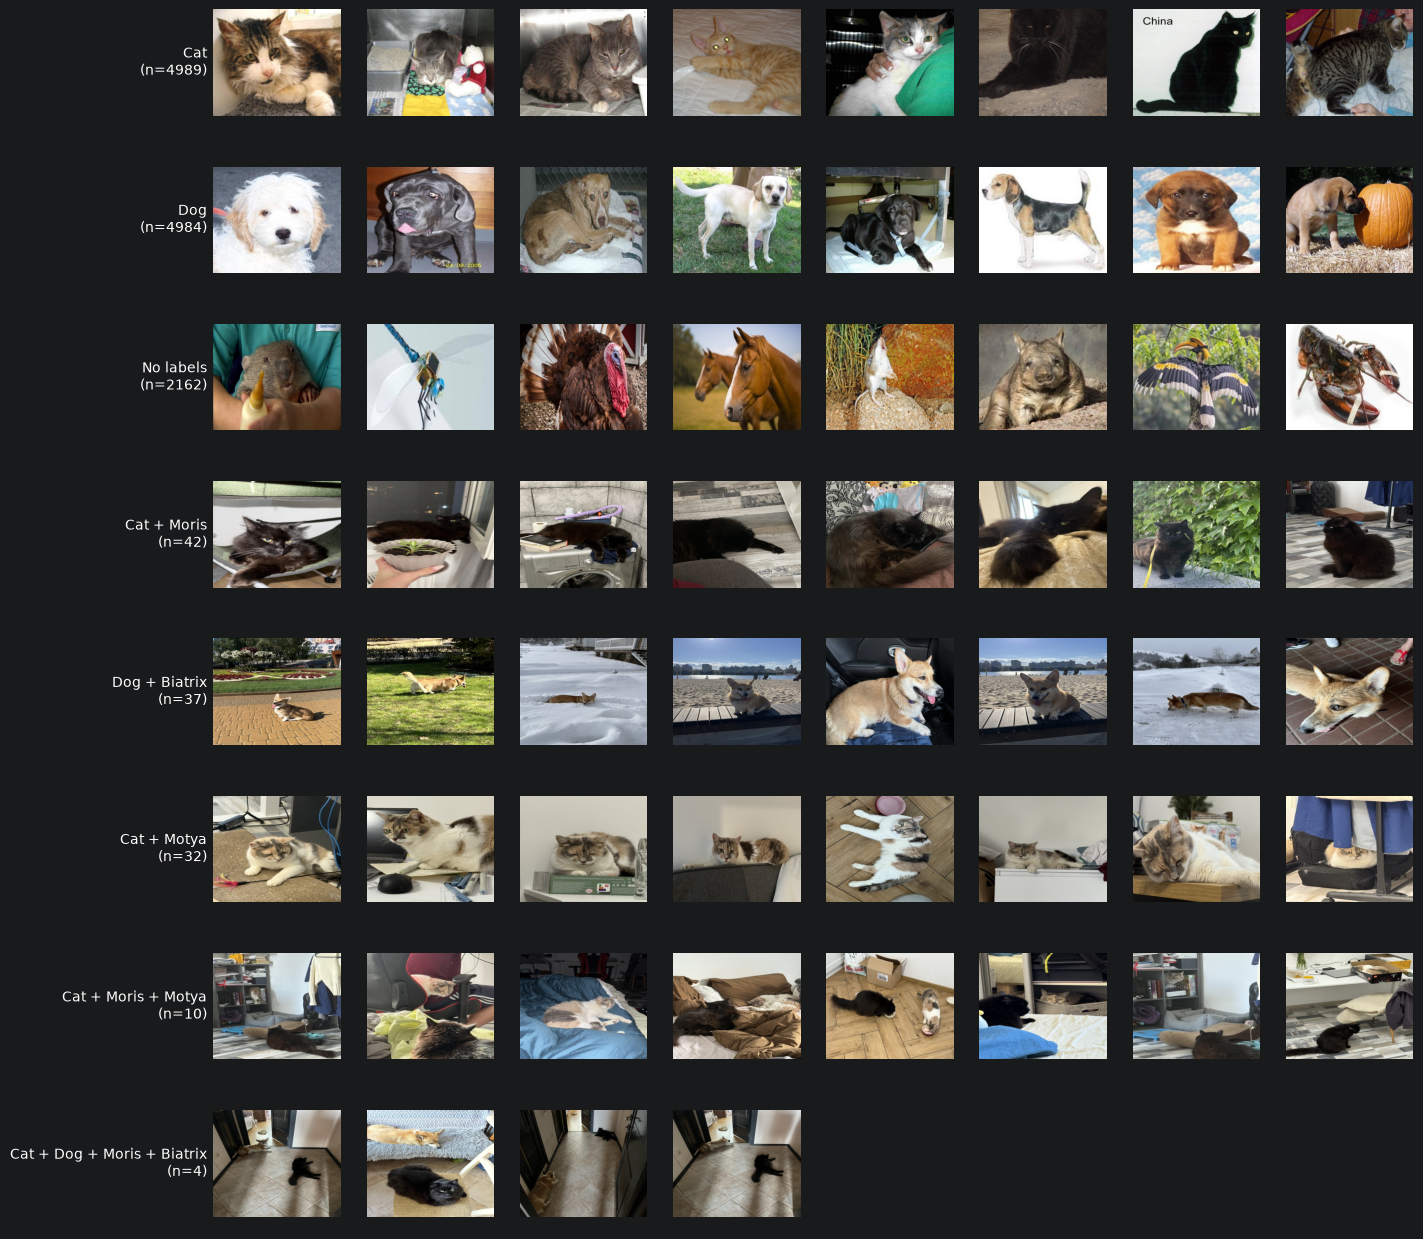

In [5]:
import matplotlib.pyplot as plt

IMAGES_PER_COMBINATION = 8

label_combinations = sorted(train.groupby(label_columns, dropna=False), key=lambda item: len(item[1]), reverse=True)

fig, axes = plt.subplots(len(label_combinations), IMAGES_PER_COMBINATION, figsize=(2 * IMAGES_PER_COMBINATION, 2 * len(label_combinations)))
for ax in axes.flat:
    ax.axis("off")

for row, (labels, rows) in enumerate(label_combinations):
    combination_name = " + ".join(c for c, value in zip(label_columns, labels) if value == 1) or "No labels"
    axes[row, 0].text(-0.05, 0.5, f"{combination_name}\n(n={len(rows)})", transform=axes[row, 0].transAxes, ha="right", va="center")
    sample_ids = rows["image_id"].sample(min(len(rows), IMAGES_PER_COMBINATION), random_state=RANDOM_STATE)
    for ax, image_id in zip(axes[row], sample_ids):
        ax.imshow(plt.imread(DATA / "train" / f"{image_id}.jpg"))

fig.subplots_adjust(left=0.15)
plt.show()

## Notes so far (work in progress)

**Data quality**
- The CSV and the image folders match exactly: no missing files, no extra files, no duplicate IDs.
- Labels are only 0 and 1, with no NaN.
- Moris and Motya are always cats. Biatrix is always a dog.
- There are 8 label combinations. Cat and Dog appear together in only 4 photos (Moris + Biatrix).

**Class imbalance** (12260 train images)
- Cat: 5077 (41.4%). Dog: 5025 (41.0%). No label: 2162 (17.6%).
- Moris: 56 (0.46%). Motya: 42 (0.34%). Biatrix: 41 (0.33%).
- The Kaggle metric is macro F1, so each of the 5 labels weighs 20%. The 3 named pets together give 60% of the score.
- Use stratified splits.

**No-label combination**
- It holds easy negatives (lobster, turkey, horses) and hard negatives (wombat, other furry animals).
- Hard negatives can cause false Cat or Dog predictions. Check errors on this combination separately.

**Photo source and background bias**
- Generic cat and dog photos look like web images: many breeds, large animal, centered.
- Moris, Motya and Biatrix look like phone photos from one home and from walks.
- Risk: the model learns the background, not the pet.

**Validation and augmentation**
- The photos of the named pets contain near-duplicates. Keep near-duplicates in the same fold to avoid leakage.
- The named pets are small in the frame. Use gentle cropping, so the animal is not cut out of the image.